In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
file_path = "Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
# 1. Display all column names 
print("Column Names: ")
print(df.columns.tolist())

# 2. View the first five records 
print(df.head())

# 3. Check the data type and non null counts
df.info()

# 4. Generate summary statistics
display(df.describe(include="all").T)

Column Names: 
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# Check missing values
print("Missing values per column:")
display(df.isnull().sum())

# Check duplicate records
print("Total duplicate rows:", df.duplicated().sum())

# Check dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Missing values per column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Total duplicate rows: 5268
Rows: 541909
Columns: 8


In [10]:
# Check cancelled invoices
print("Cancelled invoice count:")
print(df["InvoiceNo"].astype(str).str.startswith("C").sum())

# Check negative quantities
print("\nNegative quantity rows:")
print((df["Quantity"] < 0).sum())

# Check zero or negative unit prices
print("\nZero unit prices:")
print((df["UnitPrice"] == 0).sum())

print("\nNegative unit prices:")
print((df["UnitPrice"] < 0).sum())

# Inspect exact duplicate examples
display(df[df.duplicated(keep=False)].head(10))

Cancelled invoice count:
9288

Negative quantity rows:
10624

Zero unit prices:
2515

Negative unit prices:
2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [11]:
# Create a DataFrame containing cancelled invoices
cancelled = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

# Display the first 10 cancelled invoice records
display(cancelled.head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [12]:
# Select rows with negative quantities
returns = df[df["Quantity"] < 0]

# Display sample records
display(returns.head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [13]:
# Records with zero unit prices
zero_price = df[df["UnitPrice"] == 0]
display(zero_price.head(10))

# Records with negative unit prices
negative_price = df[df["UnitPrice"] < 0]
display(negative_price)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [14]:
# Preserve the original raw dataset
df_raw = df.copy()

# Create a dataset without exact duplicate rows
df_deduplicated = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_deduplicated))
print("Rows removed:", len(df) - len(df_deduplicated))

Original rows: 541909
Rows after removing duplicates: 536641
Rows removed: 5268


In [15]:
# Work with our deduplicated copy
df_clean = df_deduplicated.copy()

# Check the date range
print("First transaction:", df_clean["InvoiceDate"].min())
print("Last transaction:", df_clean["InvoiceDate"].max())

# Check the number of unique invoices
print("Unique invoices:", df_clean["InvoiceNo"].nunique())

# Check the number of unique products
print("Unique product codes:", df_clean["StockCode"].nunique())

# Check the number of countries
print("Unique countries:", df_clean["Country"].nunique())

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00
Unique invoices: 25900
Unique product codes: 4070
Unique countries: 38


In [16]:
# Check missing values after duplicate removal
print("Missing values:")
display(df_clean.isnull().sum())

# Check invoice cancellation records
cancelled_mask = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

print("Cancellation-related rows:", cancelled_mask.sum())

# Check negative quantities and unusual prices
print("Negative quantity rows:", (df_clean["Quantity"] < 0).sum())
print("Zero unit price rows:", (df_clean["UnitPrice"] == 0).sum())
print("Negative unit price rows:", (df_clean["UnitPrice"] < 0).sum())

Missing values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

Cancellation-related rows: 9251
Negative quantity rows: 10587
Zero unit price rows: 2510
Negative unit price rows: 2


In [18]:
# Calculate missing values for each column
missing_count = df_clean.isnull().sum()

# Convert counts into percentages
missing_percentage = (
    df_clean.isnull().mean() * 100
).round(2)

# Combine results into a summary table
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

display(missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
))

,Missing_Count,Missing_Percentage
CustomerID,135037,25.16
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [19]:
# Select rows with missing descriptions
missing_description = df_clean[
    df_clean["Description"].isnull()
]

# Display sample rows
display(missing_description.head(10))

# Check how many distinct stock codes are involved
print(
    "Unique stock codes with missing descriptions:",
    missing_description["StockCode"].nunique()
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


Unique stock codes with missing descriptions: 960


In [20]:
# Analyze rows with missing descriptions
print("Total rows:", len(missing_description))

print(
    "Rows with zero price:",
    (missing_description["UnitPrice"] == 0).sum()
)

print(
    "Rows with negative quantity:",
    (missing_description["Quantity"] < 0).sum()
)

print(
    "Rows with positive price:",
    (missing_description["UnitPrice"] > 0).sum()
)

# Check whether missing descriptions occur in cancelled invoices
print(
    "Cancellation-related rows:",
    missing_description["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
    .sum()
)

Total rows: 1454
Rows with zero price: 1454
Rows with negative quantity: 862
Rows with positive price: 0
Cancellation-related rows: 0


In [22]:
# Inspect records with negative unit prices
display(
    df_clean[df_clean["UnitPrice"] < 0]
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [23]:
# Inspect rows with stock code B
display(df_clean[df_clean["StockCode"] == "B"])

# Inspect invoice identifiers beginning with A
display(
    df_clean[
        df_clean["InvoiceNo"].astype(str).str.startswith("A")
    ]
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [24]:
# Select cancellation-related invoice records
cancelled = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Display a sample
display(cancelled.head(10))

# Summarize the quantities and prices
print("Cancellation-related rows:", len(cancelled))
print("Negative quantity rows:", (cancelled["Quantity"] < 0).sum())
print("Total quantity:", cancelled["Quantity"].sum())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


Cancellation-related rows: 9251
Negative quantity rows: 9251
Total quantity: -275560


In [30]:
# Start with the deduplicated dataset
df_clean = df_deduplicated.copy()

# Step 1: Exclude cancellation-related invoices
cancelled_mask = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

df_clean = df_clean.loc[~cancelled_mask].copy()

# Step 2: Exclude bad-debt adjustment records
bad_debt_mask = (
    df_clean["Description"].eq("Adjust bad debt")
)

df_clean = df_clean.loc[~bad_debt_mask].copy()

# Step 3: Exclude rows with missing descriptions
# and zero unit prices for our main product-sales analysis
sales_mask = (
    df_clean["Description"].notna()
    & df_clean["UnitPrice"].gt(0)
)

df_clean = df_clean.loc[sales_mask].copy()

print("Rows after initial cleaning:", len(df_clean))
print("Remaining cancellation rows:",
      df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Remaining bad-debt rows:",
      df_clean["Description"].eq("Adjust bad debt").sum())
print("Remaining missing descriptions:",
      df_clean["Description"].isna().sum())
print("Remaining zero or negative prices:",
      (df_clean["UnitPrice"] <= 0).sum())

Rows after initial cleaning: 524877
Remaining cancellation rows: 0
Remaining bad-debt rows: 0
Remaining missing descriptions: 0
Remaining zero or negative prices: 0


In [31]:
# Check negative quantities after initial cleaning
negative_quantity_mask = df_clean["Quantity"] < 0

print(
    "Remaining negative quantity rows:",
    negative_quantity_mask.sum()
)

# Inspect examples
display(
    df_clean.loc[
        negative_quantity_mask,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice", "Country"]
    ].head(10)
)

Remaining negative quantity rows: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country


In [32]:
display(df_clean.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [33]:
# Calculate revenue for each transaction line
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Display sample records
display(
    df_clean[
        ["InvoiceNo", "Description", "Quantity",
         "UnitPrice", "Revenue", "Country"]
    ].head(10)
)

,InvoiceNo,Description,Quantity,UnitPrice,Revenue,Country
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30,United Kingdom
1,536365,WHITE METAL LANTERN,6,3.39,20.34,United Kingdom
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00,United Kingdom
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34,United Kingdom
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34,United Kingdom
5,536365,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30,United Kingdom
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50,United Kingdom
7,536366,HAND WARMER UNION JACK,6,1.85,11.10,United Kingdom
8,536366,HAND WARMER RED POLKA DOT,6,1.85,11.10,United Kingdom
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08,United Kingdom


In [34]:
# Calculate key retail sales metrics

total_revenue = df_clean["Revenue"].sum()

total_units_sold = df_clean["Quantity"].sum()

total_transactions = df_clean["InvoiceNo"].nunique()

total_products = df_clean["StockCode"].nunique()

total_countries = df_clean["Country"].nunique()

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Unique Invoices: {total_transactions:,}")
print(f"Unique Product Codes: {total_products:,}")
print(f"Countries: {total_countries:,}")

Total Revenue: £10,631,048.74
Total Units Sold: 5,572,419
Unique Invoices: 19,959
Unique Product Codes: 3,921
Countries: 38


In [35]:
# Calculate revenue by product
top_products = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

In [36]:
# Descriptions that are not ordinary products
non_product_descriptions = [
    "DOTCOM POSTAGE",
    "POSTAGE",
    "Manual"
]

# Create a separate dataset for product analysis
product_sales = df_clean[
    ~df_clean["Description"].isin(non_product_descriptions)
].copy()

print("Product sales rows:", len(product_sales))

Product sales rows: 522728


In [37]:
top_products = (
    product_sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64

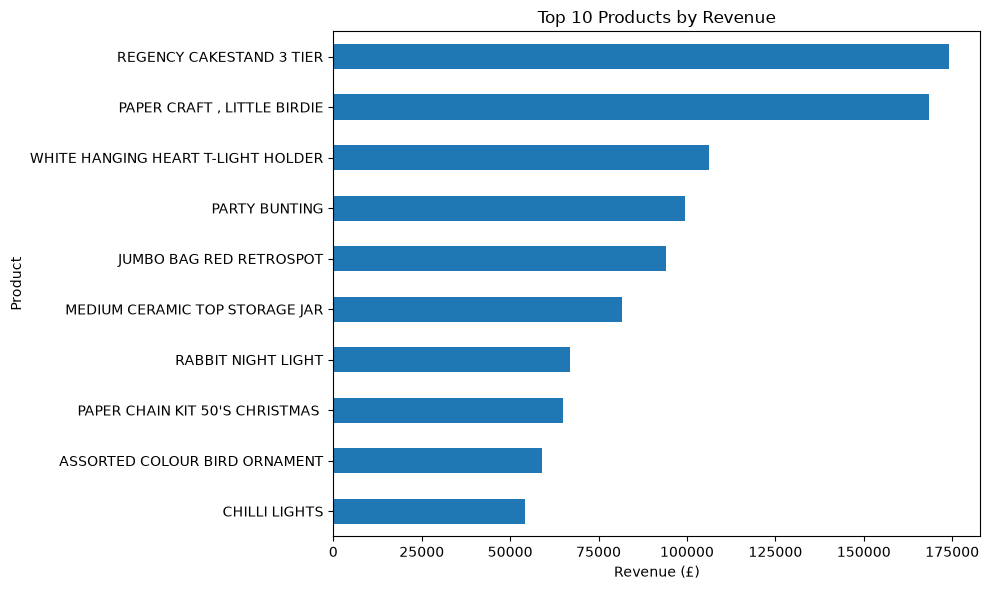

In [38]:
import matplotlib.pyplot as plt

top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [39]:
# Extract year and month from each transaction date
df_clean["YearMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

# Calculate revenue for each month
monthly_revenue = (
    df_clean.groupby("YearMonth")["Revenue"]
    .sum()
)

display(monthly_revenue)

YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     746779.320
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

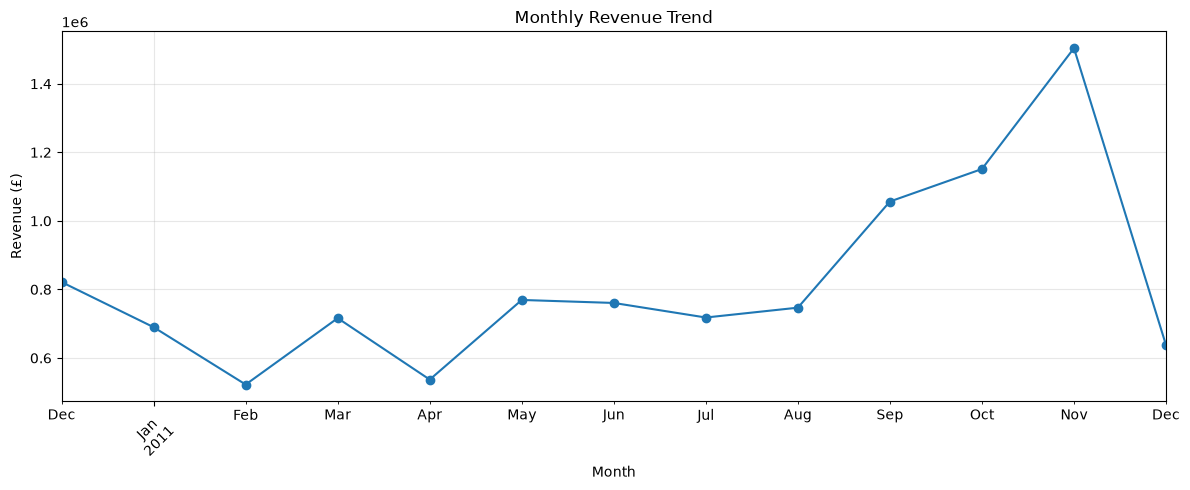

In [40]:
import matplotlib.pyplot as plt

monthly_revenue.plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
country_revenue = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(country_revenue.head(10))

Country
United Kingdom    8990682.034
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

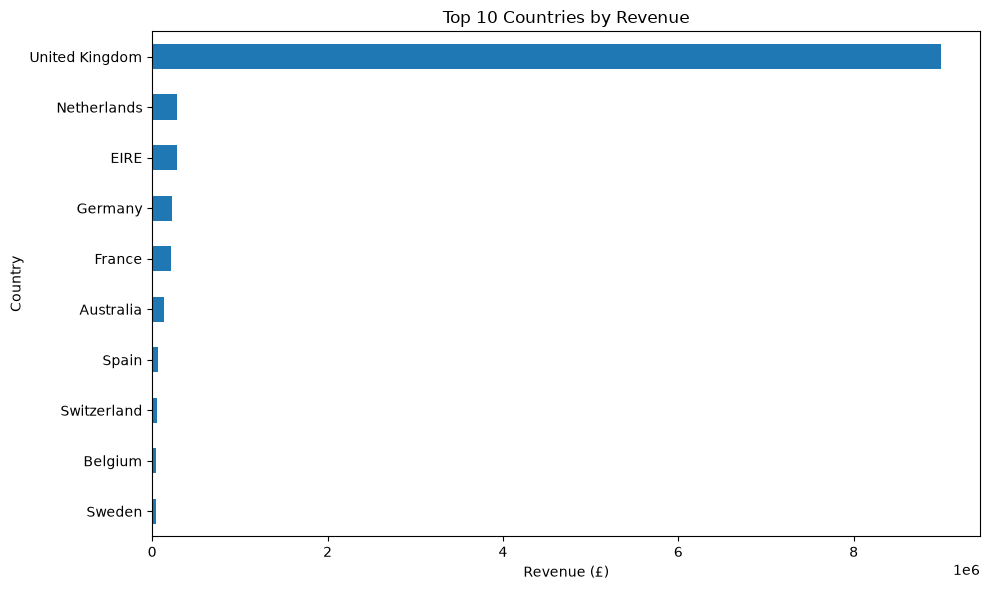

In [43]:
import matplotlib.pyplot as plt

top_countries = country_revenue.head(10)

top_countries.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [44]:
df_clean.to_csv("retail_sales_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
